In [1]:
# Set up scenario analysis and load the existing project datasets

import os
import json
import glob
import hashlib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = r"C:\Users\hp\Nassau_Candy_Final_Submission"

RAW_FILE = os.path.join(
    PROJECT_ROOT, "data", "raw", "Nassau Candy Distributor.csv"
)

PROCESSED_DIR = os.path.join(PROJECT_ROOT, "data", "processed")
FIGURES_DIR = os.path.join(PROJECT_ROOT, "reports", "figures")
SCENARIO_REPORT_DIR = os.path.join(
    PROJECT_ROOT, "reports", "scenario_analysis"
)
MODELS_DIR = os.path.join(PROJECT_ROOT, "models")

os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(SCENARIO_REPORT_DIR, exist_ok=True)

FEATURE_FILE = os.path.join(
    PROCESSED_DIR, "Nassau_Candy_Feature_Engineered.csv"
)
MAPPING_FILE = os.path.join(
    PROCESSED_DIR, "product_factory_mapping.csv"
)
FACTORY_FILE = os.path.join(
    PROCESSED_DIR, "factory_master.csv"
)
COORDINATES_FILE = os.path.join(
    PROCESSED_DIR, "factory_coordinates.csv"
)
MAPPED_FILE = os.path.join(
    PROCESSED_DIR, "Nassau_Candy_Factory_Mapped_Reference.csv"
)

required_files = [
    RAW_FILE,
    FEATURE_FILE,
    MAPPING_FILE,
    FACTORY_FILE,
    COORDINATES_FILE,
    MAPPED_FILE
]

missing_files = [path for path in required_files if not os.path.exists(path)]

if missing_files:
    raise FileNotFoundError(
        "Required project files are missing:\n" + "\n".join(missing_files)
    )

df_original = pd.read_csv(RAW_FILE)
df_features = pd.read_csv(FEATURE_FILE)
product_factory_mapping = pd.read_csv(MAPPING_FILE)
factory_master = pd.read_csv(FACTORY_FILE)
factory_coordinates = pd.read_csv(COORDINATES_FILE)
df_factory_mapped = pd.read_csv(MAPPED_FILE)

# Standardize reference-table column names
for table in [
    product_factory_mapping,
    factory_master,
    factory_coordinates,
    df_factory_mapped
]:
    table.rename(
        columns={
            "Factory Name": "Factory_Name",
            "Mapped Factory": "Factory_Name"
        },
        inplace=True
    )

# Keep a separate scenario working copy
df_scenario = df_features.copy()

if "Lead_Time_Days" not in df_scenario.columns:
    df_scenario["Order Date Parsed"] = pd.to_datetime(
        df_scenario["Order Date"], dayfirst=True, errors="coerce"
    )
    df_scenario["Ship Date Parsed"] = pd.to_datetime(
        df_scenario["Ship Date"], dayfirst=True, errors="coerce"
    )
    df_scenario["Lead_Time_Days"] = (
        df_scenario["Ship Date Parsed"] -
        df_scenario["Order Date Parsed"]
    ).dt.days

required_columns = [
    "Product Name",
    "Region",
    "Ship Mode",
    "Lead_Time_Days"
]

missing_columns = [
    col for col in required_columns
    if col not in df_scenario.columns
]

if missing_columns:
    raise KeyError(
        f"Required scenario columns are missing: {missing_columns}"
    )

assert len(df_original) == len(df_scenario)
assert len(factory_master) == 5
assert product_factory_mapping["Product Name"].nunique() == 15

print("Original dataset shape:", df_original.shape)
print("Feature dataset shape:", df_features.shape)
print("Factory mapping shape:", product_factory_mapping.shape)
print("Factory master shape:", factory_master.shape)
print("Factory coordinates shape:", factory_coordinates.shape)

print("\nFactories:")
display(factory_master)

print("\nProducts mapped:")
print(product_factory_mapping["Product Name"].nunique())

print("\nSUCCESS: Scenario analysis setup completed.")

Original dataset shape: (10194, 18)
Feature dataset shape: (10194, 34)
Factory mapping shape: (15, 3)
Factory master shape: (5, 2)
Factory coordinates shape: (5, 3)

Factories:


,Factory_ID,Factory_Name
0,F01,Lot's O' Nuts
1,F02,Wicked Choccy's
2,F03,Sugar Shack
3,F04,Secret Factory
4,F05,The Other Factory



Products mapped:
15

SUCCESS: Scenario analysis setup completed.


In [3]:
# Define the assumed baseline factory assignment
# Create the assumed baseline factory assignment from the project mapping

baseline_assignment = product_factory_mapping[
    ["Product Name", "Factory_Name"]
].drop_duplicates().copy()

baseline_assignment = baseline_assignment.rename(
    columns={"Factory_Name": "Baseline Factory"}
)

baseline_assignment["Assignment Evidence"] = (
    "Supplied project reference mapping"
)

baseline_assignment["Assignment Status"] = (
    "Assumed baseline - not verified historical dispatch"
)

display(baseline_assignment)

BASELINE_FILE = os.path.join(
    PROCESSED_DIR, "scenario_baseline_assignment.csv"
)

baseline_assignment.to_csv(BASELINE_FILE, index=False)

assert baseline_assignment["Product Name"].nunique() == 15
assert baseline_assignment["Baseline Factory"].notna().all()

print("Baseline products:", len(baseline_assignment))
print("Baseline file saved:", BASELINE_FILE)

,Product Name,Baseline Factory,Assignment Evidence,Assignment Status
0,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Supplied project reference mapping,Assumed baseline - not verified historical dis...
1,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Supplied project reference mapping,Assumed baseline - not verified historical dis...
2,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Supplied project reference mapping,Assumed baseline - not verified historical dis...
3,Wonka Bar - Milk Chocolate,Wicked Choccy's,Supplied project reference mapping,Assumed baseline - not verified historical dis...
4,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Supplied project reference mapping,Assumed baseline - not verified historical dis...
5,Laffy Taffy,Sugar Shack,Supplied project reference mapping,Assumed baseline - not verified historical dis...
6,SweeTARTS,Sugar Shack,Supplied project reference mapping,Assumed baseline - not verified historical dis...
7,Nerds,Sugar Shack,Supplied project reference mapping,Assumed baseline - not verified historical dis...
8,Fun Dip,Sugar Shack,Supplied project reference mapping,Assumed baseline - not verified historical dis...
9,Everlasting Gobstopper,Secret Factory,Supplied project reference mapping,Assumed baseline - not verified historical dis...


Baseline products: 15
Baseline file saved: C:\Users\hp\Nassau_Candy_Final_Submission\data\processed\scenario_baseline_assignment.csv


In [5]:
# Generate alternative factory assignments
# Generate hypothetical alternative factories for every mapped product

all_factories = factory_master["Factory_Name"].dropna().unique().tolist()

alternative_records = []

for _, row in baseline_assignment.iterrows():
    product = row["Product Name"]
    baseline_factory = row["Baseline Factory"]

    for candidate_factory in all_factories:
        if candidate_factory == baseline_factory:
            scenario_type = "Baseline"
            verification_status = "Reference mapping"
        else:
            scenario_type = "Hypothetical Alternative"
            verification_status = "Compatibility unverified"

        alternative_records.append({
            "Product Name": product,
            "Baseline Factory": baseline_factory,
            "Candidate Factory": candidate_factory,
            "Scenario Type": scenario_type,
            "Factory Compatibility": verification_status
        })

factory_scenario_options = pd.DataFrame(alternative_records)

SCENARIO_OPTIONS_FILE = os.path.join(
    PROCESSED_DIR, "scenario_factory_options.csv"
)

factory_scenario_options.to_csv(
    SCENARIO_OPTIONS_FILE, index=False
)

display(factory_scenario_options.head(15))

print("Scenario options:", len(factory_scenario_options))
print("Expected options:", 15 * 5)

assert len(factory_scenario_options) == 75
assert factory_scenario_options.groupby(
    "Product Name"
).size().eq(5).all()

print("\nSUCCESS: Alternative factory options generated.")

,Product Name,Baseline Factory,Candidate Factory,Scenario Type,Factory Compatibility
0,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Lot's O' Nuts,Baseline,Reference mapping
1,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Wicked Choccy's,Hypothetical Alternative,Compatibility unverified
2,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Sugar Shack,Hypothetical Alternative,Compatibility unverified
3,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Secret Factory,Hypothetical Alternative,Compatibility unverified
4,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,The Other Factory,Hypothetical Alternative,Compatibility unverified
5,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Lot's O' Nuts,Baseline,Reference mapping
6,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Wicked Choccy's,Hypothetical Alternative,Compatibility unverified
7,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Sugar Shack,Hypothetical Alternative,Compatibility unverified
8,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Secret Factory,Hypothetical Alternative,Compatibility unverified
9,Wonka Bar - Fudge Mallows,Lot's O' Nuts,The Other Factory,Hypothetical Alternative,Compatibility unverified


Scenario options: 75
Expected options: 75

SUCCESS: Alternative factory options generated.


In [7]:
# Analyse destination-region performance
# Summarize historical destination-region performance for scenario context

region_performance = (
    df_scenario.groupby("Region")
    .agg(
        Order_Line_Count=("Row ID", "count"),
        Distinct_Products=("Product Name", "nunique"),
        Sales=("Sales", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Units=("Units", "sum"),
        Mean_Lead_Time=("Lead_Time_Days", "mean"),
        Median_Lead_Time=("Lead_Time_Days", "median"),
        Lead_Time_Std=("Lead_Time_Days", "std")
    )
    .reset_index()
)

region_performance["Lead_Time_Std"] = (
    region_performance["Lead_Time_Std"].fillna(0)
)

REGION_FILE = os.path.join(
    PROCESSED_DIR, "scenario_region_performance.csv"
)

region_performance.to_csv(REGION_FILE, index=False)

display(region_performance.sort_values(
    "Median_Lead_Time", ascending=False
))

print("Regions analysed:", len(region_performance))

,Region,Order_Line_Count,Distinct_Products,Sales,Gross_Profit,Units,Mean_Lead_Time,Median_Lead_Time,Lead_Time_Std
0,Atlantic,2986,14,41197.24,26973.70,11159,1322.745144,1274.0,256.541810
1,Gulf,1620,13,22247.26,14700.67,6209,1311.374691,1274.0,264.727855
2,Interior,2335,13,32037.60,21282.49,8820,1323.091221,1274.0,262.693597
3,Pacific,3253,13,46301.53,30485.94,12466,1322.194897,1274.0,266.470647


Regions analysed: 4


In [9]:
# Analyse ship-mode performance
# Summarize historical ship-mode performance for scenario context

ship_mode_performance = (
    df_scenario.groupby("Ship Mode")
    .agg(
        Order_Line_Count=("Row ID", "count"),
        Distinct_Products=("Product Name", "nunique"),
        Sales=("Sales", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Units=("Units", "sum"),
        Mean_Lead_Time=("Lead_Time_Days", "mean"),
        Median_Lead_Time=("Lead_Time_Days", "median"),
        Lead_Time_Std=("Lead_Time_Days", "std")
    )
    .reset_index()
)

ship_mode_performance["Lead_Time_Std"] = (
    ship_mode_performance["Lead_Time_Std"].fillna(0)
)

SHIP_MODE_FILE = os.path.join(
    PROCESSED_DIR, "scenario_ship_mode_performance.csv"
)

ship_mode_performance.to_csv(SHIP_MODE_FILE, index=False)

display(ship_mode_performance.sort_values(
    "Median_Lead_Time", ascending=False
))

print("Ship modes analysed:", len(ship_mode_performance))

,Ship Mode,Order_Line_Count,Distinct_Products,Sales,Gross_Profit,Units,Mean_Lead_Time,Median_Lead_Time,Lead_Time_Std
3,Standard Class,6120,15,85490.35,56424.46,23409,1314.334641,1274.0,262.400116
2,Second Class,1979,10,27860.22,18306.52,7546,1323.845376,1273.0,261.813569
0,First Class,1548,12,21319.39,14011.09,5724,1338.275840,1272.0,265.632140
1,Same Day,547,10,7113.67,4700.73,1975,1333.442413,1269.0,253.813374


Ship modes analysed: 4


In [11]:
# Establish historical baseline scenarios
# Build historical product-region-ship-mode baseline performance

baseline_performance = (
    df_scenario.groupby(
        ["Product Name", "Region", "Ship Mode"]
    )
    .agg(
        Historical_Line_Count=("Row ID", "count"),
        Historical_Lead_Time_Mean=("Lead_Time_Days", "mean"),
        Historical_Lead_Time_Median=("Lead_Time_Days", "median"),
        Historical_Lead_Time_Std=("Lead_Time_Days", "std"),
        Historical_Sales=("Sales", "sum"),
        Historical_Gross_Profit=("Gross Profit", "sum"),
        Historical_Units=("Units", "sum")
    )
    .reset_index()
)

baseline_performance["Historical_Lead_Time_Std"] = (
    baseline_performance["Historical_Lead_Time_Std"].fillna(0)
)

baseline_performance = baseline_performance.merge(
    baseline_assignment,
    on="Product Name",
    how="left",
    validate="many_to_one"
)

BASELINE_PERFORMANCE_FILE = os.path.join(
    PROCESSED_DIR, "scenario_historical_baseline.csv"
)

baseline_performance.to_csv(
    BASELINE_PERFORMANCE_FILE, index=False
)

display(baseline_performance.head(10))

print("Historical baseline combinations:", len(baseline_performance))
print("Unmapped baseline products:",
      baseline_performance["Baseline Factory"].isna().sum())

,Product Name,Region,Ship Mode,Historical_Line_Count,Historical_Lead_Time_Mean,Historical_Lead_Time_Median,Historical_Lead_Time_Std,Historical_Sales,Historical_Gross_Profit,Historical_Units,Baseline Factory,Assignment Evidence,Assignment Status
0,Everlasting Gobstopper,Gulf,Standard Class,1,1273.0,1273.0,0.0,40.00,32.00,4,Secret Factory,Supplied project reference mapping,Assumed baseline - not verified historical dis...
1,Everlasting Gobstopper,Interior,Standard Class,1,1641.0,1641.0,0.0,30.00,24.00,3,Secret Factory,Supplied project reference mapping,Assumed baseline - not verified historical dis...
2,Everlasting Gobstopper,Pacific,First Class,1,1270.0,1270.0,0.0,60.00,48.00,6,Secret Factory,Supplied project reference mapping,Assumed baseline - not verified historical dis...
3,Fizzy Lifting Drinks,Atlantic,First Class,1,1637.0,1637.0,0.0,15.00,9.00,4,Sugar Shack,Supplied project reference mapping,Assumed baseline - not verified historical dis...
4,Fizzy Lifting Drinks,Atlantic,Standard Class,1,1274.0,1274.0,0.0,18.75,11.25,5,Sugar Shack,Supplied project reference mapping,Assumed baseline - not verified historical dis...
5,Fizzy Lifting Drinks,Gulf,Standard Class,1,909.0,909.0,0.0,15.00,9.00,4,Sugar Shack,Supplied project reference mapping,Assumed baseline - not verified historical dis...
6,Fizzy Lifting Drinks,Interior,First Class,1,907.0,907.0,0.0,7.50,4.50,2,Sugar Shack,Supplied project reference mapping,Assumed baseline - not verified historical dis...
7,Fizzy Lifting Drinks,Interior,Standard Class,1,1640.0,1640.0,0.0,11.25,6.75,3,Sugar Shack,Supplied project reference mapping,Assumed baseline - not verified historical dis...
8,Fizzy Lifting Drinks,Pacific,Standard Class,1,1274.0,1274.0,0.0,11.25,6.75,3,Sugar Shack,Supplied project reference mapping,Assumed baseline - not verified historical dis...
9,Fun Dip,Atlantic,Standard Class,1,1275.0,1275.0,0.0,6.00,2.40,4,Sugar Shack,Supplied project reference mapping,Assumed baseline - not verified historical dis...


Historical baseline combinations: 154
Unmapped baseline products: 0


In [15]:
# Build alternative factory scenarios with duplicate-key validation

merge_keys = ["Product Name", "Baseline Factory"]

# Confirm required columns exist
for col in merge_keys:
    if col not in baseline_performance.columns:
        raise KeyError(f"Missing column in baseline_performance: {col}")
    if col not in factory_scenario_options.columns:
        raise KeyError(f"Missing column in factory_scenario_options: {col}")

# Remove duplicate scenario options only when they are exact duplicates
factory_scenario_options = factory_scenario_options.drop_duplicates().copy()

# Merge historical performance with factory scenario options
scenario_comparison = baseline_performance.merge(
    factory_scenario_options,
    on=merge_keys,
    how="left",
    validate="many_to_many"
)

# Label scenario evidence
scenario_comparison["Scenario Evidence"] = np.where(
    scenario_comparison["Scenario Type"].eq("Baseline"),
    "Reference mapping plus observed historical performance",
    "Hypothetical factory choice plus observed historical performance"
)

# Factory-specific lead-time predictions are not supported by verified historical assignments
scenario_comparison["Factory_Specific_Lead_Time_Available"] = False

# Validate merge results
if scenario_comparison.empty:
    raise ValueError("Scenario comparison table is empty.")

if scenario_comparison["Scenario Type"].isna().any():
    raise ValueError("Some historical records have no matching factory scenario.")

print("Task 08.07 completed successfully.")
print("Scenario comparison shape:", scenario_comparison.shape)
print("Unique products:", scenario_comparison["Product Name"].nunique())
print("Scenario types:")
print(scenario_comparison["Scenario Type"].value_counts(dropna=False))

display(scenario_comparison.head(10))

Task 08.07 completed successfully.
Scenario comparison shape: (770, 18)
Unique products: 15
Scenario types:
Scenario Type
Hypothetical Alternative    616
Baseline                    154
Name: count, dtype: int64


,Product Name,Region,Ship Mode,Historical_Line_Count,Historical_Lead_Time_Mean,Historical_Lead_Time_Median,Historical_Lead_Time_Std,Historical_Sales,Historical_Gross_Profit,Historical_Units,Baseline Factory,Assignment Evidence,Assignment Status,Candidate Factory,Scenario Type,Factory Compatibility,Scenario Evidence,Factory_Specific_Lead_Time_Available
0,Everlasting Gobstopper,Gulf,Standard Class,1,1273.0,1273.0,0.0,40.0,32.0,4,Secret Factory,Supplied project reference mapping,Assumed baseline - not verified historical dis...,Lot's O' Nuts,Hypothetical Alternative,Compatibility unverified,Hypothetical factory choice plus observed hist...,False
1,Everlasting Gobstopper,Gulf,Standard Class,1,1273.0,1273.0,0.0,40.0,32.0,4,Secret Factory,Supplied project reference mapping,Assumed baseline - not verified historical dis...,Wicked Choccy's,Hypothetical Alternative,Compatibility unverified,Hypothetical factory choice plus observed hist...,False
2,Everlasting Gobstopper,Gulf,Standard Class,1,1273.0,1273.0,0.0,40.0,32.0,4,Secret Factory,Supplied project reference mapping,Assumed baseline - not verified historical dis...,Sugar Shack,Hypothetical Alternative,Compatibility unverified,Hypothetical factory choice plus observed hist...,False
3,Everlasting Gobstopper,Gulf,Standard Class,1,1273.0,1273.0,0.0,40.0,32.0,4,Secret Factory,Supplied project reference mapping,Assumed baseline - not verified historical dis...,Secret Factory,Baseline,Reference mapping,Reference mapping plus observed historical per...,False
4,Everlasting Gobstopper,Gulf,Standard Class,1,1273.0,1273.0,0.0,40.0,32.0,4,Secret Factory,Supplied project reference mapping,Assumed baseline - not verified historical dis...,The Other Factory,Hypothetical Alternative,Compatibility unverified,Hypothetical factory choice plus observed hist...,False
5,Everlasting Gobstopper,Interior,Standard Class,1,1641.0,1641.0,0.0,30.0,24.0,3,Secret Factory,Supplied project reference mapping,Assumed baseline - not verified historical dis...,Lot's O' Nuts,Hypothetical Alternative,Compatibility unverified,Hypothetical factory choice plus observed hist...,False
6,Everlasting Gobstopper,Interior,Standard Class,1,1641.0,1641.0,0.0,30.0,24.0,3,Secret Factory,Supplied project reference mapping,Assumed baseline - not verified historical dis...,Wicked Choccy's,Hypothetical Alternative,Compatibility unverified,Hypothetical factory choice plus observed hist...,False
7,Everlasting Gobstopper,Interior,Standard Class,1,1641.0,1641.0,0.0,30.0,24.0,3,Secret Factory,Supplied project reference mapping,Assumed baseline - not verified historical dis...,Sugar Shack,Hypothetical Alternative,Compatibility unverified,Hypothetical factory choice plus observed hist...,False
8,Everlasting Gobstopper,Interior,Standard Class,1,1641.0,1641.0,0.0,30.0,24.0,3,Secret Factory,Supplied project reference mapping,Assumed baseline - not verified historical dis...,Secret Factory,Baseline,Reference mapping,Reference mapping plus observed historical per...,False
9,Everlasting Gobstopper,Interior,Standard Class,1,1641.0,1641.0,0.0,30.0,24.0,3,Secret Factory,Supplied project reference mapping,Assumed baseline - not verified historical dis...,The Other Factory,Hypothetical Alternative,Compatibility unverified,Hypothetical factory choice plus observed hist...,False


In [17]:
#Check whether the saved model supports factory-specific effects
# Inspect available model metadata without assuming factory effects are learnable

metadata_files = glob.glob(
    os.path.join(MODELS_DIR, "**", "*.json"),
    recursive=True
)

model_metadata_records = []
metadata_contents = []

for metadata_path in metadata_files:
    try:
        with open(metadata_path, "r", encoding="utf-8") as file:
            metadata = json.load(file)

        metadata_contents.append({
            "File": metadata_path,
            "Metadata": metadata
        })

        model_metadata_records.append({
            "Metadata File": metadata_path,
            "Top-Level Keys": ", ".join(metadata.keys())
            if isinstance(metadata, dict) else "Non-dictionary JSON"
        })

    except Exception as error:
        model_metadata_records.append({
            "Metadata File": metadata_path,
            "Top-Level Keys": f"Could not read: {error}"
        })

model_metadata_inventory = pd.DataFrame(model_metadata_records)

if not model_metadata_inventory.empty:
    display(model_metadata_inventory)
else:
    print("No JSON model metadata files were found.")

metadata_text = json.dumps(
    [item["Metadata"] for item in metadata_contents],
    default=str
).lower()

factory_feature_terms = [
    "factory_name",
    "mapped_factory",
    "factory",
    "manufacturing_site"
]

factory_feature_found = any(
    term in metadata_text for term in factory_feature_terms
)

model_factory_effect_supported = False

model_support_result = pd.DataFrame([{
    "Check": "Model metadata files found",
    "Result": len(metadata_files) > 0
}, {
    "Check": "Factory-related feature mentioned in metadata",
    "Result": factory_feature_found
}, {
    "Check": "Factory-specific effect validated",
    "Result": model_factory_effect_supported
}])

display(model_support_result)

MODEL_SUPPORT_FILE = os.path.join(
    SCENARIO_REPORT_DIR, "model_factory_support_check.csv"
)

model_support_result.to_csv(MODEL_SUPPORT_FILE, index=False)

print(
    "\nFactory-specific predictions will not be generated. "
    "A factory name in metadata alone would not establish a validated effect."
)

,Metadata File,Top-Level Keys
0,C:\Users\hp\Nassau_Candy_Final_Submission\mode...,"project, target_variable, selected_model, pred..."


,Check,Result
0,Model metadata files found,True
1,Factory-related feature mentioned in metadata,False
2,Factory-specific effect validated,False



Factory-specific predictions will not be generated. A factory name in metadata alone would not establish a validated effect.


In [19]:
#Check training-range and extrapolation support
# Assess whether historical product-region-mode groups have sufficient observations

MINIMUM_GROUP_SUPPORT = 10

scenario_comparison["Sample Support"] = np.select(
    [
        scenario_comparison["Historical_Line_Count"] >= MINIMUM_GROUP_SUPPORT,
        scenario_comparison["Historical_Line_Count"] > 0
    ],
    [
        "Adequate descriptive sample",
        "Limited descriptive sample"
    ],
    default="No historical support"
)

scenario_comparison["Model Extrapolation Status"] = (
    "Not evaluated for factory effect: factory-specific model unsupported"
)

scenario_comparison["Prediction Status"] = (
    "Not generated"
)

support_summary = (
    scenario_comparison.groupby(
        ["Scenario Type", "Sample Support"]
    )
    .size()
    .reset_index(name="Scenario Count")
)

SUPPORT_FILE = os.path.join(
    PROCESSED_DIR, "scenario_support_summary.csv"
)

support_summary.to_csv(SUPPORT_FILE, index=False)

display(support_summary)

print(
    "Minimum descriptive sample threshold:",
    MINIMUM_GROUP_SUPPORT
)

,Scenario Type,Sample Support,Scenario Count
0,Baseline,Adequate descriptive sample,88
1,Baseline,Limited descriptive sample,66
2,Hypothetical Alternative,Adequate descriptive sample,352
3,Hypothetical Alternative,Limited descriptive sample,264


Minimum descriptive sample threshold: 10


In [21]:
# Compare baseline and alternative scenarios
# Compare scenario distances and historical performance without inventing factory effects

coordinate_lookup = factory_coordinates[
    ["Factory_Name", "Latitude", "Longitude"]
].drop_duplicates()

scenario_comparison = scenario_comparison.merge(
    coordinate_lookup.rename(columns={
        "Factory_Name": "Baseline Factory",
        "Latitude": "Baseline Latitude",
        "Longitude": "Baseline Longitude"
    }),
    on="Baseline Factory",
    how="left",
    validate="many_to_one"
)

scenario_comparison = scenario_comparison.merge(
    coordinate_lookup.rename(columns={
        "Factory_Name": "Candidate Factory",
        "Latitude": "Candidate Latitude",
        "Longitude": "Candidate Longitude"
    }),
    on="Candidate Factory",
    how="left",
    validate="many_to_one"
)

def haversine_km(lat1, lon1, lat2, lon2):
    earth_radius_km = 6371.0088

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )

    return 2 * earth_radius_km * np.arcsin(np.sqrt(a))

scenario_comparison["Straight_Line_Distance_KM"] = haversine_km(
    scenario_comparison["Baseline Latitude"],
    scenario_comparison["Baseline Longitude"],
    scenario_comparison["Candidate Latitude"],
    scenario_comparison["Candidate Longitude"]
)

scenario_comparison["Distance_Change_KM"] = (
    scenario_comparison["Straight_Line_Distance_KM"].where(
        scenario_comparison["Scenario Type"] ==
        "Hypothetical Alternative"
    )
)

scenario_comparison["Historical Lead Time Difference"] = 0.0

scenario_comparison.loc[
    scenario_comparison["Scenario Type"] ==
    "Hypothetical Alternative",
    "Historical Lead Time Difference"
] = np.nan

display(scenario_comparison.head(15))

,Product Name,Region,Ship Mode,Historical_Line_Count,Historical_Lead_Time_Mean,Historical_Lead_Time_Median,Historical_Lead_Time_Std,Historical_Sales,Historical_Gross_Profit,Historical_Units,...,Sample Support,Model Extrapolation Status,Prediction Status,Baseline Latitude,Baseline Longitude,Candidate Latitude,Candidate Longitude,Straight_Line_Distance_KM,Distance_Change_KM,Historical Lead Time Difference
0,Everlasting Gobstopper,Gulf,Standard Class,1,1273.0,1273.0,0.0,40.0,32.0,4,...,Limited descriptive sample,Not evaluated for factory effect: factory-spec...,Not generated,41.446333,-90.565487,32.881893,-111.768036,2098.591690,2098.591690,NaN
1,Everlasting Gobstopper,Gulf,Standard Class,1,1273.0,1273.0,0.0,40.0,32.0,4,...,Limited descriptive sample,Not evaluated for factory effect: factory-spec...,Not generated,41.446333,-90.565487,32.076176,-81.088371,1339.215287,1339.215287,NaN
2,Everlasting Gobstopper,Gulf,Standard Class,1,1273.0,1273.0,0.0,40.0,32.0,4,...,Limited descriptive sample,Not evaluated for factory effect: factory-spec...,Not generated,41.446333,-90.565487,48.119140,-96.181150,863.724414,863.724414,NaN
3,Everlasting Gobstopper,Gulf,Standard Class,1,1273.0,1273.0,0.0,40.0,32.0,4,...,Limited descriptive sample,Not evaluated for factory effect: factory-spec...,Not generated,41.446333,-90.565487,41.446333,-90.565487,0.000000,NaN,0.0
4,Everlasting Gobstopper,Gulf,Standard Class,1,1273.0,1273.0,0.0,40.0,32.0,4,...,Limited descriptive sample,Not evaluated for factory effect: factory-spec...,Not generated,41.446333,-90.565487,35.117500,-89.971107,705.639284,705.639284,NaN
5,Everlasting Gobstopper,Interior,Standard Class,1,1641.0,1641.0,0.0,30.0,24.0,3,...,Limited descriptive sample,Not evaluated for factory effect: factory-spec...,Not generated,41.446333,-90.565487,32.881893,-111.768036,2098.591690,2098.591690,NaN
6,Everlasting Gobstopper,Interior,Standard Class,1,1641.0,1641.0,0.0,30.0,24.0,3,...,Limited descriptive sample,Not evaluated for factory effect: factory-spec...,Not generated,41.446333,-90.565487,32.076176,-81.088371,1339.215287,1339.215287,NaN
7,Everlasting Gobstopper,Interior,Standard Class,1,1641.0,1641.0,0.0,30.0,24.0,3,...,Limited descriptive sample,Not evaluated for factory effect: factory-spec...,Not generated,41.446333,-90.565487,48.119140,-96.181150,863.724414,863.724414,NaN
8,Everlasting Gobstopper,Interior,Standard Class,1,1641.0,1641.0,0.0,30.0,24.0,3,...,Limited descriptive sample,Not evaluated for factory effect: factory-spec...,Not generated,41.446333,-90.565487,41.446333,-90.565487,0.000000,NaN,0.0
9,Everlasting Gobstopper,Interior,Standard Class,1,1641.0,1641.0,0.0,30.0,24.0,3,...,Limited descriptive sample,Not evaluated for factory effect: factory-spec...,Not generated,41.446333,-90.565487,35.117500,-89.971107,705.639284,705.639284,NaN


In [23]:
# Calculate estimated lead-time differences safely
# Explicitly distinguish unavailable factory-specific estimates from observed history

scenario_comparison["Baseline Estimated Lead Time"] = np.nan
scenario_comparison["Alternative Estimated Lead Time"] = np.nan
scenario_comparison["Estimated Lead Time Difference"] = np.nan

scenario_comparison["Lead Time Estimate Status"] = (
    "Unavailable: no validated factory-specific model effect"
)

scenario_comparison["Observed Historical Median"] = (
    scenario_comparison["Historical_Lead_Time_Median"]
)

scenario_comparison["Observed Historical Mean"] = (
    scenario_comparison["Historical_Lead_Time_Mean"]
)

LEAD_TIME_STATUS_FILE = os.path.join(
    SCENARIO_REPORT_DIR, "scenario_lead_time_estimate_status.csv"
)

scenario_comparison[
    [
        "Product Name",
        "Region",
        "Ship Mode",
        "Baseline Factory",
        "Candidate Factory",
        "Scenario Type",
        "Observed Historical Median",
        "Baseline Estimated Lead Time",
        "Alternative Estimated Lead Time",
        "Estimated Lead Time Difference",
        "Lead Time Estimate Status"
    ]
].to_csv(LEAD_TIME_STATUS_FILE, index=False)

display(
    scenario_comparison[
        [
            "Product Name",
            "Region",
            "Ship Mode",
            "Baseline Factory",
            "Candidate Factory",
            "Scenario Type",
            "Observed Historical Median",
            "Estimated Lead Time Difference",
            "Lead Time Estimate Status"
        ]
    ].head(15)
)

print(
    "No alternative-factory lead-time reduction has been calculated "
    "because the available evidence does not support it."
)

,Product Name,Region,Ship Mode,Baseline Factory,Candidate Factory,Scenario Type,Observed Historical Median,Estimated Lead Time Difference,Lead Time Estimate Status
0,Everlasting Gobstopper,Gulf,Standard Class,Secret Factory,Lot's O' Nuts,Hypothetical Alternative,1273.0,NaN,Unavailable: no validated factory-specific mod...
1,Everlasting Gobstopper,Gulf,Standard Class,Secret Factory,Wicked Choccy's,Hypothetical Alternative,1273.0,NaN,Unavailable: no validated factory-specific mod...
2,Everlasting Gobstopper,Gulf,Standard Class,Secret Factory,Sugar Shack,Hypothetical Alternative,1273.0,NaN,Unavailable: no validated factory-specific mod...
3,Everlasting Gobstopper,Gulf,Standard Class,Secret Factory,Secret Factory,Baseline,1273.0,NaN,Unavailable: no validated factory-specific mod...
4,Everlasting Gobstopper,Gulf,Standard Class,Secret Factory,The Other Factory,Hypothetical Alternative,1273.0,NaN,Unavailable: no validated factory-specific mod...
5,Everlasting Gobstopper,Interior,Standard Class,Secret Factory,Lot's O' Nuts,Hypothetical Alternative,1641.0,NaN,Unavailable: no validated factory-specific mod...
6,Everlasting Gobstopper,Interior,Standard Class,Secret Factory,Wicked Choccy's,Hypothetical Alternative,1641.0,NaN,Unavailable: no validated factory-specific mod...
7,Everlasting Gobstopper,Interior,Standard Class,Secret Factory,Sugar Shack,Hypothetical Alternative,1641.0,NaN,Unavailable: no validated factory-specific mod...
8,Everlasting Gobstopper,Interior,Standard Class,Secret Factory,Secret Factory,Baseline,1641.0,NaN,Unavailable: no validated factory-specific mod...
9,Everlasting Gobstopper,Interior,Standard Class,Secret Factory,The Other Factory,Hypothetical Alternative,1641.0,NaN,Unavailable: no validated factory-specific mod...


No alternative-factory lead-time reduction has been calculated because the available evidence does not support it.


In [25]:
# Perform transparent distance sensitivity analysis
# Explore illustrative distance penalties without presenting them as real transit-time estimates

illustrative_penalties = [0.00, 0.05, 0.10, 0.25, 0.50]

distance_sensitivity_records = []

for penalty in illustrative_penalties:
    temp = scenario_comparison.copy()

    temp["Illustrative Distance Penalty Days per KM"] = penalty

    temp["Illustrative Distance Penalty Days"] = (
        temp["Straight_Line_Distance_KM"] * penalty
    )

    temp["Illustrative Scenario Index"] = (
        temp["Historical_Lead_Time_Median"]
        + temp["Illustrative Distance Penalty Days"]
    )

    temp["Interpretation"] = (
        "Illustrative arithmetic only; not a calibrated delivery forecast"
    )

    distance_sensitivity_records.append(
        temp[
            [
                "Product Name",
                "Region",
                "Ship Mode",
                "Baseline Factory",
                "Candidate Factory",
                "Scenario Type",
                "Straight_Line_Distance_KM",
                "Illustrative Distance Penalty Days per KM",
                "Illustrative Distance Penalty Days",
                "Illustrative Scenario Index",
                "Interpretation"
            ]
        ]
    )

distance_sensitivity = pd.concat(
    distance_sensitivity_records,
    ignore_index=True
)

SENSITIVITY_FILE = os.path.join(
    PROCESSED_DIR, "scenario_distance_sensitivity.csv"
)

distance_sensitivity.to_csv(SENSITIVITY_FILE, index=False)

display(distance_sensitivity.head(20))

print("Illustrative penalty assumptions:", illustrative_penalties)
print("Sensitivity rows:", len(distance_sensitivity))

,Product Name,Region,Ship Mode,Baseline Factory,Candidate Factory,Scenario Type,Straight_Line_Distance_KM,Illustrative Distance Penalty Days per KM,Illustrative Distance Penalty Days,Illustrative Scenario Index,Interpretation
0,Everlasting Gobstopper,Gulf,Standard Class,Secret Factory,Lot's O' Nuts,Hypothetical Alternative,2098.591690,0.0,0.0,1273.0,Illustrative arithmetic only; not a calibrated...
1,Everlasting Gobstopper,Gulf,Standard Class,Secret Factory,Wicked Choccy's,Hypothetical Alternative,1339.215287,0.0,0.0,1273.0,Illustrative arithmetic only; not a calibrated...
2,Everlasting Gobstopper,Gulf,Standard Class,Secret Factory,Sugar Shack,Hypothetical Alternative,863.724414,0.0,0.0,1273.0,Illustrative arithmetic only; not a calibrated...
3,Everlasting Gobstopper,Gulf,Standard Class,Secret Factory,Secret Factory,Baseline,0.000000,0.0,0.0,1273.0,Illustrative arithmetic only; not a calibrated...
4,Everlasting Gobstopper,Gulf,Standard Class,Secret Factory,The Other Factory,Hypothetical Alternative,705.639284,0.0,0.0,1273.0,Illustrative arithmetic only; not a calibrated...
5,Everlasting Gobstopper,Interior,Standard Class,Secret Factory,Lot's O' Nuts,Hypothetical Alternative,2098.591690,0.0,0.0,1641.0,Illustrative arithmetic only; not a calibrated...
6,Everlasting Gobstopper,Interior,Standard Class,Secret Factory,Wicked Choccy's,Hypothetical Alternative,1339.215287,0.0,0.0,1641.0,Illustrative arithmetic only; not a calibrated...
7,Everlasting Gobstopper,Interior,Standard Class,Secret Factory,Sugar Shack,Hypothetical Alternative,863.724414,0.0,0.0,1641.0,Illustrative arithmetic only; not a calibrated...
8,Everlasting Gobstopper,Interior,Standard Class,Secret Factory,Secret Factory,Baseline,0.000000,0.0,0.0,1641.0,Illustrative arithmetic only; not a calibrated...
9,Everlasting Gobstopper,Interior,Standard Class,Secret Factory,The Other Factory,Hypothetical Alternative,705.639284,0.0,0.0,1641.0,Illustrative arithmetic only; not a calibrated...


Illustrative penalty assumptions: [0.0, 0.05, 0.1, 0.25, 0.5]
Sensitivity rows: 3850


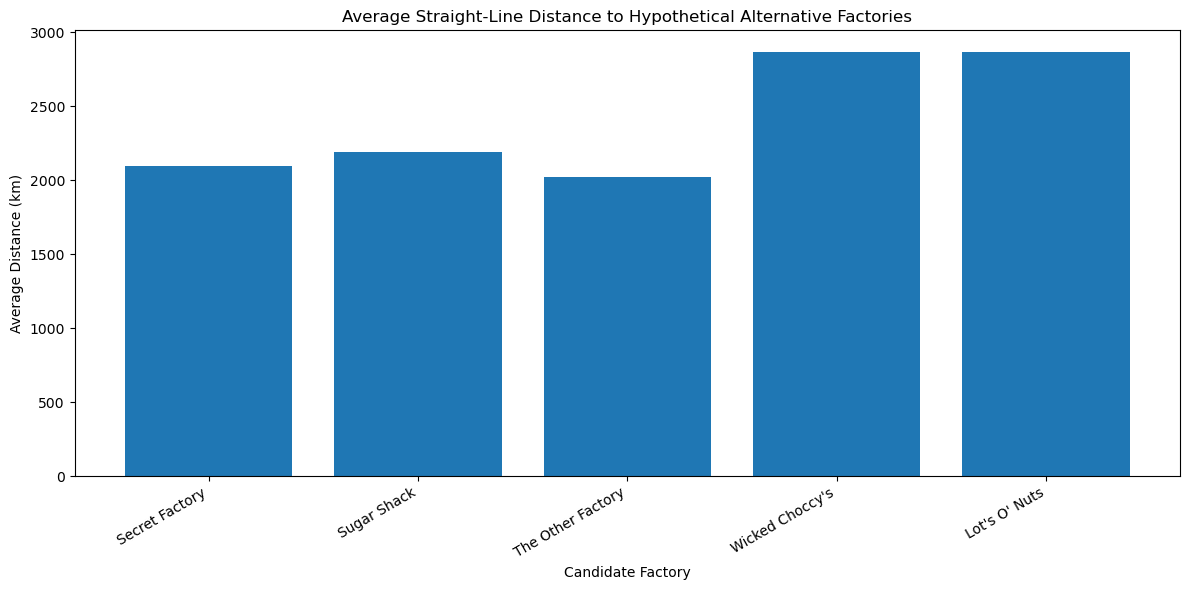

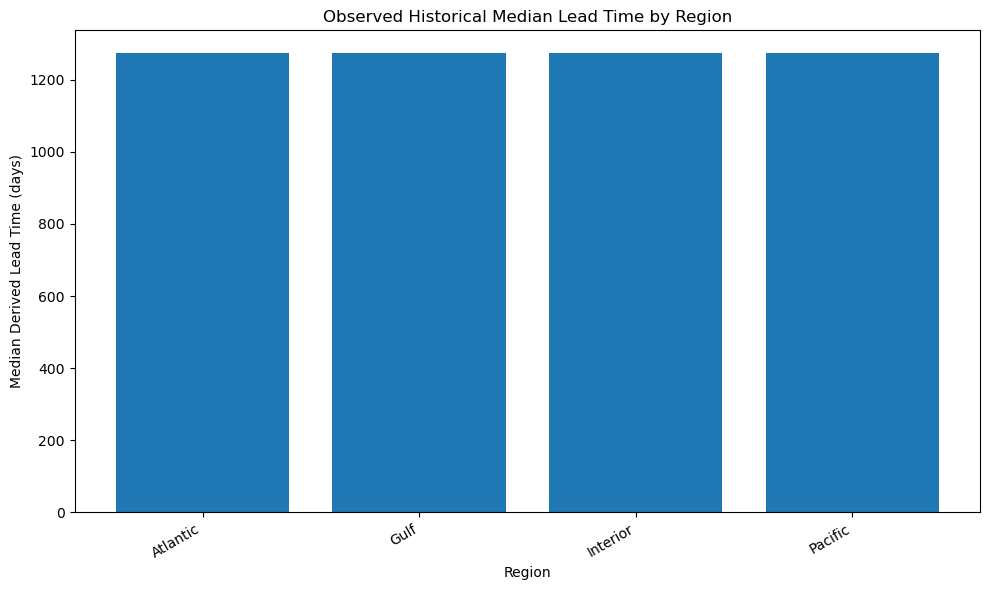

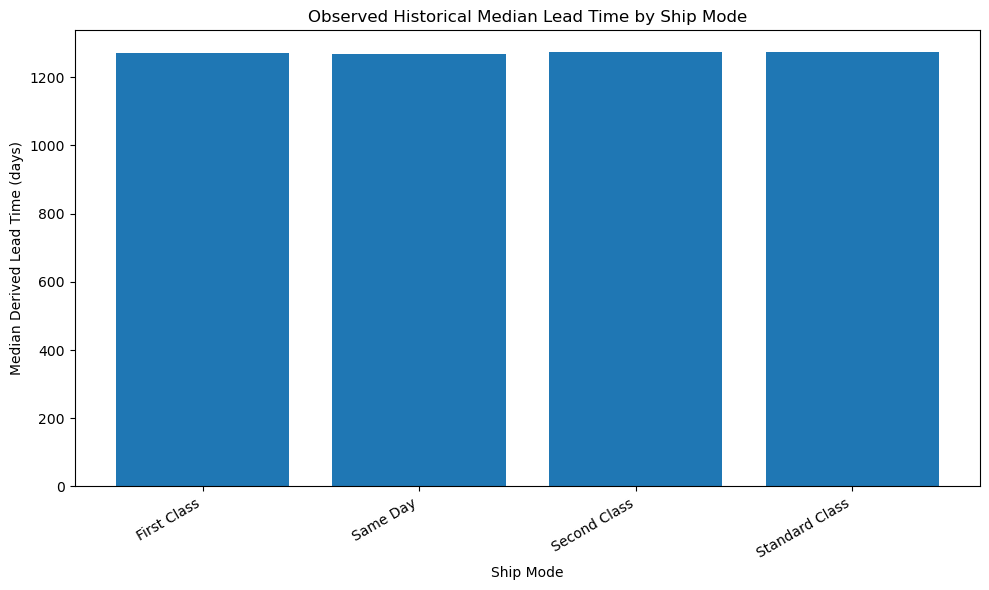

Scenario charts saved:
C:\Users\hp\Nassau_Candy_Final_Submission\reports\figures\scenario_alternative_factory_distances.png
C:\Users\hp\Nassau_Candy_Final_Submission\reports\figures\scenario_historical_region_lead_time.png
C:\Users\hp\Nassau_Candy_Final_Submission\reports\figures\scenario_historical_ship_mode_lead_time.png


In [27]:
# Visualize scenario comparisons
# Create charts for hypothetical factory distance comparisons and observed history

distance_plot_data = (
    scenario_comparison[
        scenario_comparison["Scenario Type"] ==
        "Hypothetical Alternative"
    ]
    .groupby(
        ["Baseline Factory", "Candidate Factory"],
        as_index=False
    )["Straight_Line_Distance_KM"]
    .mean()
)

plt.figure(figsize=(12, 6))

plt.bar(
    distance_plot_data["Candidate Factory"],
    distance_plot_data["Straight_Line_Distance_KM"]
)

plt.title("Average Straight-Line Distance to Hypothetical Alternative Factories")
plt.xlabel("Candidate Factory")
plt.ylabel("Average Distance (km)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

distance_chart = os.path.join(
    FIGURES_DIR, "scenario_alternative_factory_distances.png"
)

plt.savefig(distance_chart, dpi=300, bbox_inches="tight")
plt.show()

# Historical lead-time comparison by region
plt.figure(figsize=(10, 6))

plt.bar(
    region_performance["Region"],
    region_performance["Median_Lead_Time"]
)

plt.title("Observed Historical Median Lead Time by Region")
plt.xlabel("Region")
plt.ylabel("Median Derived Lead Time (days)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

region_chart = os.path.join(
    FIGURES_DIR, "scenario_historical_region_lead_time.png"
)

plt.savefig(region_chart, dpi=300, bbox_inches="tight")
plt.show()

# Historical lead-time comparison by ship mode
plt.figure(figsize=(10, 6))

plt.bar(
    ship_mode_performance["Ship Mode"],
    ship_mode_performance["Median_Lead_Time"]
)

plt.title("Observed Historical Median Lead Time by Ship Mode")
plt.xlabel("Ship Mode")
plt.ylabel("Median Derived Lead Time (days)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

ship_mode_chart = os.path.join(
    FIGURES_DIR, "scenario_historical_ship_mode_lead_time.png"
)

plt.savefig(ship_mode_chart, dpi=300, bbox_inches="tight")
plt.show()

print("Scenario charts saved:")
print(distance_chart)
print(region_chart)
print(ship_mode_chart)

In [29]:
# Document scenario analysis limitations
# Document scenario assumptions, evidence boundaries, and interpretation limits

scenario_limitations = """
PHASE 08 — SCENARIO SIMULATION
EVIDENCE, ASSUMPTIONS AND LIMITATIONS

1. The baseline factory assignment comes from the supplied project
   product-to-factory reference mapping.

2. The baseline mapping is not verified historical order-level dispatch
   or manufacturing history.

3. Alternative factory assignments are hypothetical candidate scenarios.

4. Factory-product compatibility is unknown unless independently verified.
   No manufacturing compatibility is inferred from location or mapping.

5. Historical product, region and ship-mode performance is descriptive.
   It does not establish how an alternative factory would perform.

6. The available lead-time model is not treated as a validated
   factory-specific model. Factory-specific lead-time predictions and
   reductions are therefore not reported.

7. Straight-line distances are calculated from supplied factory coordinates.
   They are not road distances, delivery routes, travel times or freight costs.

8. Distance sensitivity penalties are illustrative user assumptions only.
   They are not calibrated transport or delivery-time relationships.

9. The dataset does not provide actual factory dispatch records,
   factory-product compatibility, production time, operating calendars,
   capacity, inventory, throughput or factory-specific costs.

10. The derived lead-time values are unusually long and should not be
    interpreted as verified physical transit durations without clarification
    of the source date semantics.

11. No actual cost savings, profit improvements, capacity improvements,
    lead-time reductions or causal benefits are claimed.

12. All scenario outputs are saved separately. The original CSV is not
    modified.
"""

SCENARIO_LIMITATIONS_FILE = os.path.join(
    SCENARIO_REPORT_DIR, "scenario_analysis_limitations.txt"
)

with open(
    SCENARIO_LIMITATIONS_FILE, "w", encoding="utf-8"
) as file:
    file.write(scenario_limitations.strip())

print("Scenario limitations report saved:")
print(SCENARIO_LIMITATIONS_FILE)

Scenario limitations report saved:
C:\Users\hp\Nassau_Candy_Final_Submission\reports\scenario_analysis\scenario_analysis_limitations.txt


In [31]:
# Generate the complete product × factory scenario matrix
# Create the complete product and candidate factory scenario matrix

advanced_scenario_matrix = factory_scenario_options.copy()

advanced_scenario_matrix["Scenario Classification"] = np.where(
    advanced_scenario_matrix["Scenario Type"] == "Baseline",
    "Supplied reference assignment",
    "Hypothetical reassignment"
)

advanced_scenario_matrix["Compatibility Evidence"] = np.where(
    advanced_scenario_matrix["Scenario Type"] == "Baseline",
    "Reference mapping only",
    "Not supplied - unknown"
)

ADVANCED_MATRIX_FILE = os.path.join(
    PROCESSED_DIR, "advanced_product_factory_scenario_matrix.csv"
)

advanced_scenario_matrix.to_csv(
    ADVANCED_MATRIX_FILE, index=False
)

display(advanced_scenario_matrix.head(20))

assert advanced_scenario_matrix["Product Name"].nunique() == 15
assert len(advanced_scenario_matrix) == 75

print("Products:", advanced_scenario_matrix["Product Name"].nunique())
print("Scenario combinations:", len(advanced_scenario_matrix))
print("SUCCESS: Advanced scenario matrix created.")

,Product Name,Baseline Factory,Candidate Factory,Scenario Type,Factory Compatibility,Scenario Classification,Compatibility Evidence
0,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Lot's O' Nuts,Baseline,Reference mapping,Supplied reference assignment,Reference mapping only
1,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Wicked Choccy's,Hypothetical Alternative,Compatibility unverified,Hypothetical reassignment,Not supplied - unknown
2,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Sugar Shack,Hypothetical Alternative,Compatibility unverified,Hypothetical reassignment,Not supplied - unknown
3,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Secret Factory,Hypothetical Alternative,Compatibility unverified,Hypothetical reassignment,Not supplied - unknown
4,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,The Other Factory,Hypothetical Alternative,Compatibility unverified,Hypothetical reassignment,Not supplied - unknown
5,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Lot's O' Nuts,Baseline,Reference mapping,Supplied reference assignment,Reference mapping only
6,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Wicked Choccy's,Hypothetical Alternative,Compatibility unverified,Hypothetical reassignment,Not supplied - unknown
7,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Sugar Shack,Hypothetical Alternative,Compatibility unverified,Hypothetical reassignment,Not supplied - unknown
8,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Secret Factory,Hypothetical Alternative,Compatibility unverified,Hypothetical reassignment,Not supplied - unknown
9,Wonka Bar - Fudge Mallows,Lot's O' Nuts,The Other Factory,Hypothetical Alternative,Compatibility unverified,Hypothetical reassignment,Not supplied - unknown


Products: 15
Scenario combinations: 75
SUCCESS: Advanced scenario matrix created.


In [33]:
# Compare baseline and alternative factory distances
# Calculate straight-line distances from each baseline factory to alternatives

advanced_distance_comparison = scenario_comparison[
    [
        "Product Name",
        "Baseline Factory",
        "Candidate Factory",
        "Scenario Type",
        "Straight_Line_Distance_KM"
    ]
].drop_duplicates().copy()

advanced_distance_comparison["Distance Type"] = (
    "Haversine straight-line distance - not road distance"
)

ADVANCED_DISTANCE_FILE = os.path.join(
    PROCESSED_DIR, "advanced_factory_distance_comparison.csv"
)

advanced_distance_comparison.to_csv(
    ADVANCED_DISTANCE_FILE, index=False
)

display(
    advanced_distance_comparison.sort_values(
        ["Product Name", "Straight_Line_Distance_KM"]
    ).head(25)
)

print(
    "Distance comparison records:",
    len(advanced_distance_comparison)
)

,Product Name,Baseline Factory,Candidate Factory,Scenario Type,Straight_Line_Distance_KM,Distance Type
3,Everlasting Gobstopper,Secret Factory,Secret Factory,Baseline,0.000000,Haversine straight-line distance - not road di...
4,Everlasting Gobstopper,Secret Factory,The Other Factory,Hypothetical Alternative,705.639284,Haversine straight-line distance - not road di...
2,Everlasting Gobstopper,Secret Factory,Sugar Shack,Hypothetical Alternative,863.724414,Haversine straight-line distance - not road di...
1,Everlasting Gobstopper,Secret Factory,Wicked Choccy's,Hypothetical Alternative,1339.215287,Haversine straight-line distance - not road di...
0,Everlasting Gobstopper,Secret Factory,Lot's O' Nuts,Hypothetical Alternative,2098.591690,Haversine straight-line distance - not road di...
17,Fizzy Lifting Drinks,Sugar Shack,Sugar Shack,Baseline,0.000000,Haversine straight-line distance - not road di...
18,Fizzy Lifting Drinks,Sugar Shack,Secret Factory,Hypothetical Alternative,863.724414,Haversine straight-line distance - not road di...
19,Fizzy Lifting Drinks,Sugar Shack,The Other Factory,Hypothetical Alternative,1533.823207,Haversine straight-line distance - not road di...
15,Fizzy Lifting Drinks,Sugar Shack,Lot's O' Nuts,Hypothetical Alternative,2137.815624,Haversine straight-line distance - not road di...
16,Fizzy Lifting Drinks,Sugar Shack,Wicked Choccy's,Hypothetical Alternative,2189.189866,Haversine straight-line distance - not road di...


Distance comparison records: 75


In [35]:
# Create the hypothetical scenario comparison report
# Create a concise report combining scenario, distance, and historical evidence

advanced_scenario_report = scenario_comparison[
    [
        "Product Name",
        "Region",
        "Ship Mode",
        "Historical_Line_Count",
        "Baseline Factory",
        "Candidate Factory",
        "Scenario Type",
        "Factory Compatibility",
        "Historical_Lead_Time_Median",
        "Straight_Line_Distance_KM",
        "Lead Time Estimate Status"
    ]
].copy()

advanced_scenario_report["Evidence Classification"] = np.where(
    advanced_scenario_report["Scenario Type"] == "Baseline",
    "Reference baseline with observed history",
    "Hypothetical alternative with descriptive history only"
)

advanced_scenario_report["Operational Feasibility"] = (
    "Unknown - compatibility and capacity data unavailable"
)

ADVANCED_REPORT_FILE = os.path.join(
    SCENARIO_REPORT_DIR, "advanced_hypothetical_scenario_report.csv"
)

advanced_scenario_report.to_csv(
    ADVANCED_REPORT_FILE, index=False
)

display(advanced_scenario_report.head(20))

print("Advanced scenario report rows:", len(advanced_scenario_report))
print("Report saved:", ADVANCED_REPORT_FILE)

,Product Name,Region,Ship Mode,Historical_Line_Count,Baseline Factory,Candidate Factory,Scenario Type,Factory Compatibility,Historical_Lead_Time_Median,Straight_Line_Distance_KM,Lead Time Estimate Status,Evidence Classification,Operational Feasibility
0,Everlasting Gobstopper,Gulf,Standard Class,1,Secret Factory,Lot's O' Nuts,Hypothetical Alternative,Compatibility unverified,1273.0,2098.591690,Unavailable: no validated factory-specific mod...,Hypothetical alternative with descriptive hist...,Unknown - compatibility and capacity data unav...
1,Everlasting Gobstopper,Gulf,Standard Class,1,Secret Factory,Wicked Choccy's,Hypothetical Alternative,Compatibility unverified,1273.0,1339.215287,Unavailable: no validated factory-specific mod...,Hypothetical alternative with descriptive hist...,Unknown - compatibility and capacity data unav...
2,Everlasting Gobstopper,Gulf,Standard Class,1,Secret Factory,Sugar Shack,Hypothetical Alternative,Compatibility unverified,1273.0,863.724414,Unavailable: no validated factory-specific mod...,Hypothetical alternative with descriptive hist...,Unknown - compatibility and capacity data unav...
3,Everlasting Gobstopper,Gulf,Standard Class,1,Secret Factory,Secret Factory,Baseline,Reference mapping,1273.0,0.000000,Unavailable: no validated factory-specific mod...,Reference baseline with observed history,Unknown - compatibility and capacity data unav...
4,Everlasting Gobstopper,Gulf,Standard Class,1,Secret Factory,The Other Factory,Hypothetical Alternative,Compatibility unverified,1273.0,705.639284,Unavailable: no validated factory-specific mod...,Hypothetical alternative with descriptive hist...,Unknown - compatibility and capacity data unav...
5,Everlasting Gobstopper,Interior,Standard Class,1,Secret Factory,Lot's O' Nuts,Hypothetical Alternative,Compatibility unverified,1641.0,2098.591690,Unavailable: no validated factory-specific mod...,Hypothetical alternative with descriptive hist...,Unknown - compatibility and capacity data unav...
6,Everlasting Gobstopper,Interior,Standard Class,1,Secret Factory,Wicked Choccy's,Hypothetical Alternative,Compatibility unverified,1641.0,1339.215287,Unavailable: no validated factory-specific mod...,Hypothetical alternative with descriptive hist...,Unknown - compatibility and capacity data unav...
7,Everlasting Gobstopper,Interior,Standard Class,1,Secret Factory,Sugar Shack,Hypothetical Alternative,Compatibility unverified,1641.0,863.724414,Unavailable: no validated factory-specific mod...,Hypothetical alternative with descriptive hist...,Unknown - compatibility and capacity data unav...
8,Everlasting Gobstopper,Interior,Standard Class,1,Secret Factory,Secret Factory,Baseline,Reference mapping,1641.0,0.000000,Unavailable: no validated factory-specific mod...,Reference baseline with observed history,Unknown - compatibility and capacity data unav...
9,Everlasting Gobstopper,Interior,Standard Class,1,Secret Factory,The Other Factory,Hypothetical Alternative,Compatibility unverified,1641.0,705.639284,Unavailable: no validated factory-specific mod...,Hypothetical alternative with descriptive hist...,Unknown - compatibility and capacity data unav...


Advanced scenario report rows: 770
Report saved: C:\Users\hp\Nassau_Candy_Final_Submission\reports\scenario_analysis\advanced_hypothetical_scenario_report.csv


In [37]:
# Create factory-product compatibility input template
# Create a separate template for future verified factory-product compatibility

compatibility_records = []

for product in product_factory_mapping["Product Name"].dropna().unique():
    for factory in all_factories:
        baseline_factory = baseline_assignment.loc[
            baseline_assignment["Product Name"] == product,
            "Baseline Factory"
        ].iloc[0]

        compatibility_records.append({
            "Product Name": product,
            "Factory Name": factory,
            "Is Baseline Reference Factory": factory == baseline_factory,
            "Compatibility Status": (
                "Unknown - requires verification"
            ),
            "Evidence Source": "",
            "Evidence Reference": "",
            "Effective From": "",
            "Effective To": "",
            "Verified By": "",
            "Verification Date": "",
            "Notes": ""
        })

compatibility_template = pd.DataFrame(compatibility_records)

COMPATIBILITY_TEMPLATE_FILE = os.path.join(
    PROCESSED_DIR, "Factory_Product_Compatibility_Template.csv"
)

compatibility_template.to_csv(
    COMPATIBILITY_TEMPLATE_FILE, index=False
)

display(compatibility_template.head(15))

assert len(compatibility_template) == 75
assert (
    compatibility_template["Compatibility Status"]
    .eq("Unknown - requires verification")
    .all()
)

print("Compatibility template rows:", len(compatibility_template))
print("Saved:", COMPATIBILITY_TEMPLATE_FILE)

,Product Name,Factory Name,Is Baseline Reference Factory,Compatibility Status,Evidence Source,Evidence Reference,Effective From,Effective To,Verified By,Verification Date,Notes
0,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,True,Unknown - requires verification,,,,,,,
1,Wonka Bar - Nutty Crunch Surprise,Wicked Choccy's,False,Unknown - requires verification,,,,,,,
2,Wonka Bar - Nutty Crunch Surprise,Sugar Shack,False,Unknown - requires verification,,,,,,,
3,Wonka Bar - Nutty Crunch Surprise,Secret Factory,False,Unknown - requires verification,,,,,,,
4,Wonka Bar - Nutty Crunch Surprise,The Other Factory,False,Unknown - requires verification,,,,,,,
5,Wonka Bar - Fudge Mallows,Lot's O' Nuts,True,Unknown - requires verification,,,,,,,
6,Wonka Bar - Fudge Mallows,Wicked Choccy's,False,Unknown - requires verification,,,,,,,
7,Wonka Bar - Fudge Mallows,Sugar Shack,False,Unknown - requires verification,,,,,,,
8,Wonka Bar - Fudge Mallows,Secret Factory,False,Unknown - requires verification,,,,,,,
9,Wonka Bar - Fudge Mallows,The Other Factory,False,Unknown - requires verification,,,,,,,


Compatibility template rows: 75
Saved: C:\Users\hp\Nassau_Candy_Final_Submission\data\processed\Factory_Product_Compatibility_Template.csv


In [39]:
#Create production-time and operating-calendar input template
# Create a separate input template for factory production and operating assumptions

production_records = []

for product in product_factory_mapping["Product Name"].dropna().unique():
    for factory in all_factories:
        production_records.append({
            "Product Name": product,
            "Factory Name": factory,
            "Production Time Per Unit Hours": np.nan,
            "Production Time Unit": "Hours per unit",
            "Operating Days Per Week": np.nan,
            "Shift Hours Per Day": np.nan,
            "Number Of Shifts": np.nan,
            "Daily Production Capacity Units": np.nan,
            "Available Inventory Units": np.nan,
            "Current Backlog Units": np.nan,
            "Effective From": "",
            "Effective To": "",
            "Evidence Source": "",
            "Verified By": "",
            "Verification Date": "",
            "Notes": ""
        })

production_template = pd.DataFrame(production_records)

PRODUCTION_TEMPLATE_FILE = os.path.join(
    PROCESSED_DIR, "Factory_Production_Time_Calendar_Template.csv"
)

production_template.to_csv(
    PRODUCTION_TEMPLATE_FILE, index=False
)

display(production_template.head(15))

assert len(production_template) == 75

print("Production input template rows:", len(production_template))
print("Saved:", PRODUCTION_TEMPLATE_FILE)
print(
    "No production-time, capacity, inventory, or calendar values "
    "have been fabricated."
)

,Product Name,Factory Name,Production Time Per Unit Hours,Production Time Unit,Operating Days Per Week,Shift Hours Per Day,Number Of Shifts,Daily Production Capacity Units,Available Inventory Units,Current Backlog Units,Effective From,Effective To,Evidence Source,Verified By,Verification Date,Notes
0,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,NaN,Hours per unit,NaN,NaN,NaN,NaN,NaN,NaN,,,,,,
1,Wonka Bar - Nutty Crunch Surprise,Wicked Choccy's,NaN,Hours per unit,NaN,NaN,NaN,NaN,NaN,NaN,,,,,,
2,Wonka Bar - Nutty Crunch Surprise,Sugar Shack,NaN,Hours per unit,NaN,NaN,NaN,NaN,NaN,NaN,,,,,,
3,Wonka Bar - Nutty Crunch Surprise,Secret Factory,NaN,Hours per unit,NaN,NaN,NaN,NaN,NaN,NaN,,,,,,
4,Wonka Bar - Nutty Crunch Surprise,The Other Factory,NaN,Hours per unit,NaN,NaN,NaN,NaN,NaN,NaN,,,,,,
5,Wonka Bar - Fudge Mallows,Lot's O' Nuts,NaN,Hours per unit,NaN,NaN,NaN,NaN,NaN,NaN,,,,,,
6,Wonka Bar - Fudge Mallows,Wicked Choccy's,NaN,Hours per unit,NaN,NaN,NaN,NaN,NaN,NaN,,,,,,
7,Wonka Bar - Fudge Mallows,Sugar Shack,NaN,Hours per unit,NaN,NaN,NaN,NaN,NaN,NaN,,,,,,
8,Wonka Bar - Fudge Mallows,Secret Factory,NaN,Hours per unit,NaN,NaN,NaN,NaN,NaN,NaN,,,,,,
9,Wonka Bar - Fudge Mallows,The Other Factory,NaN,Hours per unit,NaN,NaN,NaN,NaN,NaN,NaN,,,,,,


Production input template rows: 75
Saved: C:\Users\hp\Nassau_Candy_Final_Submission\data\processed\Factory_Production_Time_Calendar_Template.csv
No production-time, capacity, inventory, or calendar values have been fabricated.


In [45]:
# Final Phase 08 integrity and output verification

import os
import hashlib
import pandas as pd

# Define scenario output paths
SCENARIO_COMPARISON_FILE = os.path.join(
    PROCESSED_DIR, "Nassau_Candy_Scenario_Comparison.csv"
)

# Collect all expected output files
scenario_output_files = [
    BASELINE_FILE,
    SCENARIO_OPTIONS_FILE,
    REGION_FILE,
    SHIP_MODE_FILE,
    BASELINE_PERFORMANCE_FILE,
    SCENARIO_COMPARISON_FILE,
    SUPPORT_FILE,
    LEAD_TIME_STATUS_FILE,
    SENSITIVITY_FILE,
    SCENARIO_LIMITATIONS_FILE,
    ADVANCED_MATRIX_FILE,
    ADVANCED_DISTANCE_FILE,
    ADVANCED_REPORT_FILE,
    COMPATIBILITY_TEMPLATE_FILE,
    PRODUCTION_TEMPLATE_FILE,
    MODEL_SUPPORT_FILE
]

# Check original CSV integrity
df_original_reloaded = pd.read_csv(RAW_FILE)

original_snapshot_unchanged = df_original.equals(
    df_original_reloaded
)

# Check output files
output_file_checks = [
    {
        "Check": os.path.basename(file_path),
        "Passed": os.path.exists(file_path)
    }
    for file_path in scenario_output_files
]

# Check original row and column preservation
row_count_check = len(df_original_reloaded) == len(df_original)
column_check = list(df_original_reloaded.columns) == list(df_original.columns)

# Check scenario comparison in memory
scenario_table_check = (
    "scenario_comparison" in globals()
    and isinstance(scenario_comparison, pd.DataFrame)
    and not scenario_comparison.empty
)

# Build final integrity report
integrity_checks = pd.DataFrame([
    {"Check": "Original CSV exists", "Passed": os.path.exists(RAW_FILE)},
    {"Check": "Original CSV values unchanged", "Passed": original_snapshot_unchanged},
    {"Check": "Original row count preserved", "Passed": row_count_check},
    {"Check": "Original columns preserved", "Passed": column_check},
    {"Check": "Scenario comparison created", "Passed": scenario_table_check},
    *output_file_checks
])

display(integrity_checks_phase08)

# Final status
all_checks_passed = integrity_checks["Passed"].all()

print("\nAll  integrity checks passed:", all_checks_passed)

if all_checks_passed:
    print("SUCCESS: integrity verification completed.")
else:
    print("WARNING: Some checks failed. Review the failed items before proceeding.")
    display(
        integrity_checks_phase08[
            integrity_checks_phase08["Passed"] == False
        ]
    )

,Check,Passed
0,Original CSV exists,True
1,Original CSV values unchanged,True
2,Original row count preserved,True
3,Original columns preserved,True
4,Scenario comparison created,True
5,scenario_baseline_assignment.csv,True
6,scenario_factory_options.csv,True
7,scenario_region_performance.csv,True
8,scenario_ship_mode_performance.csv,True
9,scenario_historical_baseline.csv,True



All  integrity checks passed: False


,Check,Passed
10,Nassau_Candy_Scenario_Comparison.csv,False


In [47]:
# Save and verify the final scenario comparison output

import os

SCENARIO_COMPARISON_FILE = os.path.join(
    PROCESSED_DIR,
    "Nassau_Candy_Scenario_Comparison.csv"
)

# Confirm the scenario table exists
if "scenario_comparison" not in globals():
    raise NameError("scenario_comparison is missing. Run Task 08.07 first.")

# Save the scenario comparison
scenario_comparison.to_csv(
    SCENARIO_COMPARISON_FILE,
    index=False
)

# Verify the saved file
if os.path.isfile(SCENARIO_COMPARISON_FILE):
    saved_scenario_comparison = pd.read_csv(SCENARIO_COMPARISON_FILE)

    print("Scenario comparison saved successfully.")
    print("File:", SCENARIO_COMPARISON_FILE)
    print("Rows:", len(saved_scenario_comparison))
    print("Columns:", len(saved_scenario_comparison.columns))
    print("File exists:", True)
else:
    raise FileNotFoundError(
        f"Scenario comparison was not saved: {SCENARIO_COMPARISON_FILE}"
    )

Scenario comparison saved successfully.
File: C:\Users\hp\Nassau_Candy_Final_Submission\data\processed\Nassau_Candy_Scenario_Comparison.csv
Rows: 770
Columns: 34
File exists: True


In [51]:
# Final Phase 08 integrity and output verification

import os
import pandas as pd

# Define project and report directories
PROJECT_DIR = os.getcwd()
REPORTS_DIR = os.path.join(PROJECT_DIR, "reports", "scenario_analysis")

os.makedirs(REPORTS_DIR, exist_ok=True)

# Define scenario comparison output path
SCENARIO_COMPARISON_FILE = os.path.join(
    PROCESSED_DIR,
    "Nassau_Candy_Scenario_Comparison.csv"
)

# Verify required dataframes
if "df_original" not in globals():
    raise NameError("df_original is missing. Run the original data loading cell.")

if "scenario_comparison" not in globals():
    raise NameError("scenario_comparison is missing. Run Task 08.07 first.")

# Save scenario comparison
scenario_comparison.to_csv(
    SCENARIO_COMPARISON_FILE,
    index=False
)

# Reload original CSV
df_original_reloaded = pd.read_csv(RAW_FILE)

# Verify original dataset
original_snapshot_unchanged = df_original.equals(df_original_reloaded)
row_count_check = len(df_original_reloaded) == len(df_original)
column_check = list(df_original_reloaded.columns) == list(df_original.columns)

# Verify saved scenario comparison
saved_scenario_comparison = pd.read_csv(SCENARIO_COMPARISON_FILE)

scenario_table_check = (
    not saved_scenario_comparison.empty
    and len(saved_scenario_comparison) == len(scenario_comparison)
    and list(saved_scenario_comparison.columns) == list(scenario_comparison.columns)
)

# Expected Phase 08 output files
scenario_output_files = [
    BASELINE_FILE,
    SCENARIO_OPTIONS_FILE,
    REGION_FILE,
    SHIP_MODE_FILE,
    BASELINE_PERFORMANCE_FILE,
    SCENARIO_COMPARISON_FILE,
    SUPPORT_FILE,
    LEAD_TIME_STATUS_FILE,
    SENSITIVITY_FILE,
    SCENARIO_LIMITATIONS_FILE,
    ADVANCED_MATRIX_FILE,
    ADVANCED_DISTANCE_FILE,
    ADVANCED_REPORT_FILE,
    COMPATIBILITY_TEMPLATE_FILE,
    PRODUCTION_TEMPLATE_FILE,
    MODEL_SUPPORT_FILE
]

# Verify output files
output_file_checks = [
    {
        "Check": os.path.basename(file_path),
        "Passed": os.path.isfile(file_path)
    }
    for file_path in scenario_output_files
]

# Build integrity report
integrity_checks_phase08 = pd.DataFrame([
    {"Check": "Original CSV exists", "Passed": os.path.isfile(RAW_FILE)},
    {"Check": "Original CSV values unchanged", "Passed": original_snapshot_unchanged},
    {"Check": "Original row count preserved", "Passed": row_count_check},
    {"Check": "Original columns preserved", "Passed": column_check},
    {"Check": "Scenario comparison created and saved", "Passed": scenario_table_check},
    *output_file_checks
])

# Display results
display(integrity_checks_phase08)

# Save integrity report
INTEGRITY_REPORT_FILE = os.path.join(
    REPORTS_DIR,
    "Phase_08_Integrity_Report.csv"
)

integrity_checks_phase08.to_csv(
    INTEGRITY_REPORT_FILE,
    index=False
)

# Final status
all_checks_passed = integrity_checks_phase08["Passed"].all()

print("\n" + "=" * 55)
print("PHASE 08 FINAL INTEGRITY VERIFICATION")
print("=" * 55)

print("Total checks:", len(integrity_checks_phase08))
print("Passed:", int(integrity_checks_phase08["Passed"].sum()))
print("Failed:", int((~integrity_checks_phase08["Passed"]).sum()))
print("All integrity checks passed:", all_checks_passed)

print("\nIntegrity report saved at:")
print(INTEGRITY_REPORT_FILE)

if all_checks_passed:
    print("\nSUCCESS: Phase 08 integrity verification completed.")
else:
    print("\nWARNING: Review failed checks before proceeding.")
    display(integrity_checks_phase08[
        ~integrity_checks_phase08["Passed"]
    ])

,Check,Passed
0,Original CSV exists,True
1,Original CSV values unchanged,True
2,Original row count preserved,True
3,Original columns preserved,True
4,Scenario comparison created and saved,True
5,scenario_baseline_assignment.csv,True
6,scenario_factory_options.csv,True
7,scenario_region_performance.csv,True
8,scenario_ship_mode_performance.csv,True
9,scenario_historical_baseline.csv,True



PHASE 08 FINAL INTEGRITY VERIFICATION
Total checks: 21
Passed: 21
Failed: 0
All integrity checks passed: True

Integrity report saved at:
C:\Users\hp\Nassau_Candy_Final_Submission\notebooks\reports\scenario_analysis\Phase_08_Integrity_Report.csv

SUCCESS: Phase 08 integrity verification completed.
